# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [11]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things
import math

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [12]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [ ]:

xi = np.array((7.2, 7.4, 7.6, 7.8))  # x-coordinates of the interpolation points

# Get the corresponding y-values from the original function
yi = y[np.digitize(xi, x)]


def lagrange_pol(x, x_i, f_i):
    # Initialize an array of ones for the Lagrange basis polynomials
    l_i = np.ones((len(x_i), len(x)))

    # Calculate each Lagrange basis polynomial L_i(x)
    for i in range(len(x_i)):
        for j in range(len(x_i)):
            # Skip the term where i = j to avoid division by zero
            if i != j:
                # Multiply by (x - x_j) / (x_i - x_j)
                l_i[i] *= ((x - x_i[j]) / (x_i[i] - x_i[j]))

    # Multiply each basis polynomial by its corresponding function value
    # and sum them to obtain the interpolating polynomial
    return np.sum(l_i * f_i[:, None], axis=0)


def max_err(x, dfx, x_i):
    # Initialize an array for the product (x - x_0)(x - x_1)...(x - x_n)
    diff_products = np.ones(len(x))

    # Calculate the product of the differences for every x-value
    for i in range(len(x_i)):
        diff_products *= x - x_i[i]

    # Calculate the maximum interpolation error estimate:
    # E(x) <= max(|f^(n+1)(x)|) / (n+1)! * max(|product of differences|)
    return (np.max(np.abs(dfx)) / math.factorial(len(x_i))) * np.max(np.abs(diff_products))


# Generate 1000 equally spaced points between the first and last interpolation points
x_err = np.linspace(7.2, 7.8, 1000)

# Calculate the fourth derivative of the function:
# f(x) = cos(-2*pi*x) + 0.4*x^2
# f''''(x) = (2*pi)^4 * cos(-2*pi*x)
err = max_err(
    x_err,
    (2 * np.pi)**4 * np.cos(-2 * np.pi * x_err),
    xi
)

# Print the estimated maximum absolute interpolation error
print(f"Maximum absolute error estimate: {err}")

Maximum absolute error estimate: 0.10390266782115787


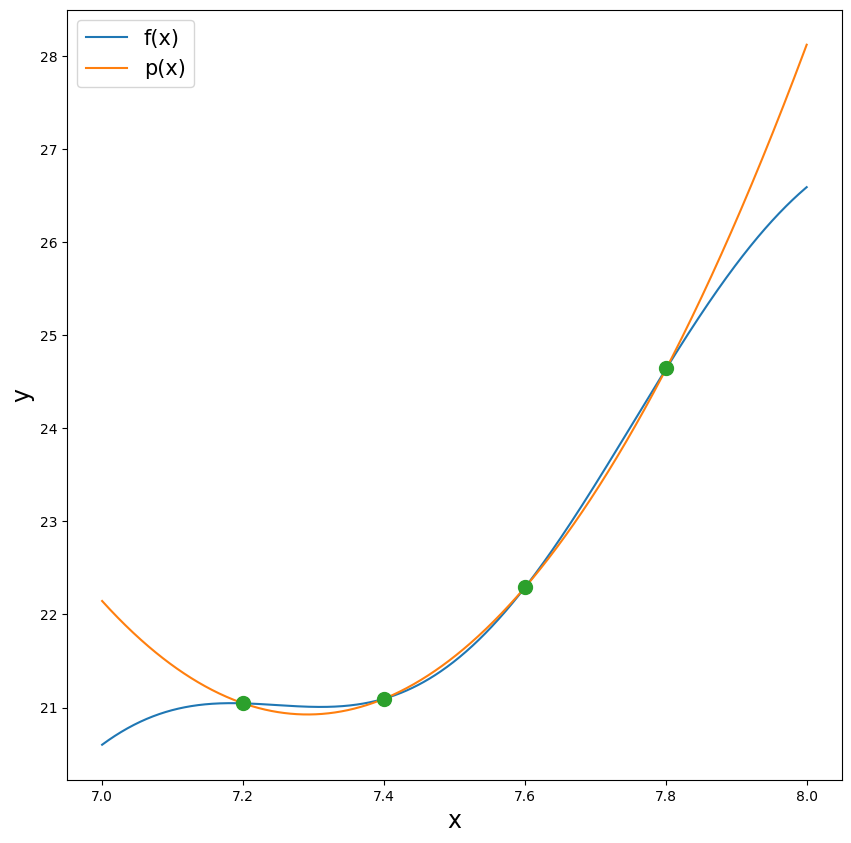

In [14]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(x,lagrange_pol(x, xi, yi),label='p(x)') 
plt.plot(xi,yi,'o',markersize=10)
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)


## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$?

In [15]:
# Generate 1000 equally spaced x-values in the interval [0, 2]
x_2 = np.linspace(0, 2, 1000)

# Calculate the corresponding function values: y(x) = pi * x^7
y_2 = np.pi * x_2**7


def max_err_lin(x, y, err):
    # Start with 2 interpolation points (one linear interval)
    d = 2

    while True:
        # Generate d equally spaced interpolation points
        x_i = np.linspace(np.min(x), np.max(x), d)

        # Calculate the function values at the interpolation points
        y_i = np.pi * x_i**7

        # Initialize an array to store the interpolated values
        f = np.empty_like(y)

        # Perform linear interpolation between every pair of neighbouring points
        for i in range(len(x_i) - 1):

            # For all intervals except the last one, exclude the right endpoint
            # to avoid assigning a point to two different intervals
            if i < len(x_i) - 2:
                mask = (x >= x_i[i]) & (x < x_i[i + 1])

            # Include the right endpoint for the last interval
            else:
                mask = (x >= x_i[i]) & (x <= x_i[i + 1])

            # Calculate the slope between the two interpolation points
            slope = (y_i[i + 1] - y_i[i]) / (x_i[i + 1] - x_i[i])

            # Calculate the linear interpolation for all x-values in this interval
            f[mask] = slope * (x[mask] - x_i[i]) + y_i[i]

        # Convert the interpolated values into a one-dimensional array
        f = f.flatten()

        # Calculate the maximum absolute difference between
        # the original function and the interpolated function
        if np.max(np.abs(y - f)) < err:

            # Return the step size between neighbouring interpolation points
            return (np.max(x_i) - np.min(x_i)) / (d - 1)

        # If the error is too large, increase the number of interpolation points
        # and repeat the interpolation
        d += 1


# Determine the step size required to achieve a maximum error below 10^-6
step = max_err_lin(x_2, y_2, 1e-6)

# Print the resulting step size
print(f"Step size: {step}")

Step size: 0.002002002002002002


Sadly, my code takes too long to evaluate enough points, so I had to use np.interp()

In [16]:
# Generate 100000 equally spaced x-values in the interval [0, 2]
x_2 = np.linspace(0, 2, 100000)

# Calculate the corresponding function values: y(x) = pi * x^7
y_2 = np.pi * x_2**7


def max_err_lin(x, y, err):
    # Start with 2 interpolation points (one linear interval)
    d = 2

    while True:
        # Generate d equally spaced interpolation points
        x_i = np.linspace(np.min(x), np.max(x), d)

        # Calculate the function values at the interpolation points
        y_i = np.pi * x_i**7

        # Perform piecewise linear interpolation at the original x-values
        # np.interp automatically finds the appropriate interval for each x-value
        f = np.interp(x, x_i, y_i)

        # Calculate the maximum absolute difference between
        # the original function and the interpolated function
        if np.max(np.abs(y - f)) < err:

            # Return the step size between neighbouring interpolation points
            return (x_i[-1] - x_i[0]) / (d - 1)

        # If the error is too large, increase the number of interpolation points
        # and repeat the interpolation
        d += 1


# Determine the step size required for a maximum absolute error below 10^-6
step = max_err_lin(x_2, y_2, 1e-6)

# Print the resulting step size
print(f"Step size: {step}")


Step size: 4.3551161727239074e-05


Or just use the formula

In [17]:
# Calculate the maximum allowed step size using the theoretical
# error bound for linear interpolation:
# E_max <= (d^2 / 8) * max(|f''(x)|)
# Rearranging for d gives:
# d < sqrt(8 * E_max / max(|f''(x)|))
#
# For f(x) = pi * x^7, the second derivative is:
# f''(x) = 42 * pi * x^5

d_limit = np.sqrt(1e-6 / (np.max(42 * np.pi * x_2**5) / 8))

# Calculate the minimum number of intervals required to cover [0, 2]
# using the maximum allowed step size
# math.ceil() rounds up to the next integer
n = math.ceil((np.max(x_2) - np.min(x_2)) / d_limit)

# Print the maximum allowed step size
print(f"Step Size must be smaller than {d_limit}")

# Print the minimum number of intervals required
print(f"Number of intervals: at least {n}")

Step Size must be smaller than 4.3528171377568164e-05
Number of intervals: at least 45948


## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

Text(0, 0.5, 'y')

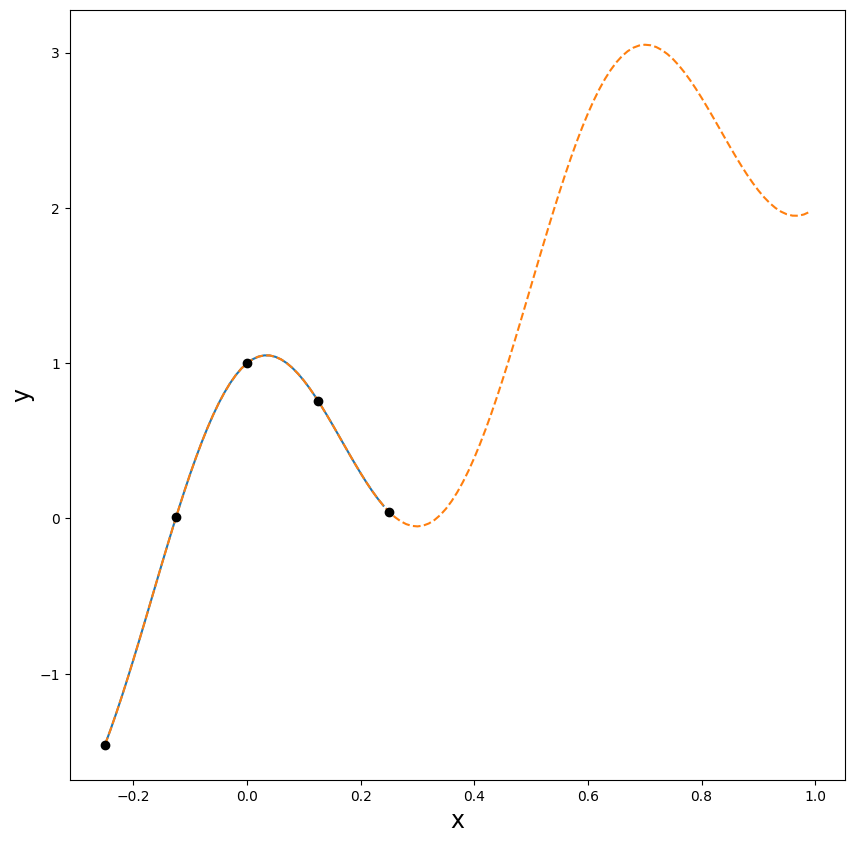

In [18]:
xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi
plt.figure(figsize=(10,10))
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--')
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)

----------------------------------------------------------

In [19]:
import sympy as sp

# Define the symbolic variable x
x = sp.symbols("x")

# Generate 1000 equally spaced points in the interval [-0.25, 0.25]
x_values = np.linspace(-0.25, 0.25, 1000)

# Define the function symbolically: f(x) = cos(-3*pi*x) + 3*x
f = sp.cos(-3 * np.pi * x) + 3 * x


def max_err_taylor(x_values, a, f, limit):
    # Start with the original function (zeroth derivative)
    df = f
    j = 0

    while True:
        # Calculate the next derivative of the function
        df = df.diff(x)

        # Evaluate the derivative at all points in the given interval
        df_values = [df.subs({x: point}) for point in x_values]

        # Calculate the maximum Taylor error estimate:
        # E_j(x) <= |(x-a)^(j+1) / (j+1)! * f^(j+1)(x)|
        max_err = np.max(np.abs(
            ((x_values - a)**(j + 1) / math.factorial(j + 1)) * df_values
        ))

        # Check whether the maximum error is below the specified tolerance
        if max_err < limit:
            # Return the required polynomial order and its maximum error estimate
            return j, max_err

        # If the error is too large, increase the polynomial order
        j += 1


# Determine the minimum Taylor polynomial order required
# for an error smaller than 10^-6, expanding around a = 0
j, max_err = max_err_taylor(x_values, 0, f, 1e-6)

# Print the required polynomial order
print(f"Polynomial order: {j}")

    

Polynomial order: 14


## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


Triangular interpolation: zr = 1.144061815475188
Bilinear interpolation: zr = 0.8966629920417069


Text(0.3707315720886276, 0.5723724295546504, '($x_r,y_r)$')

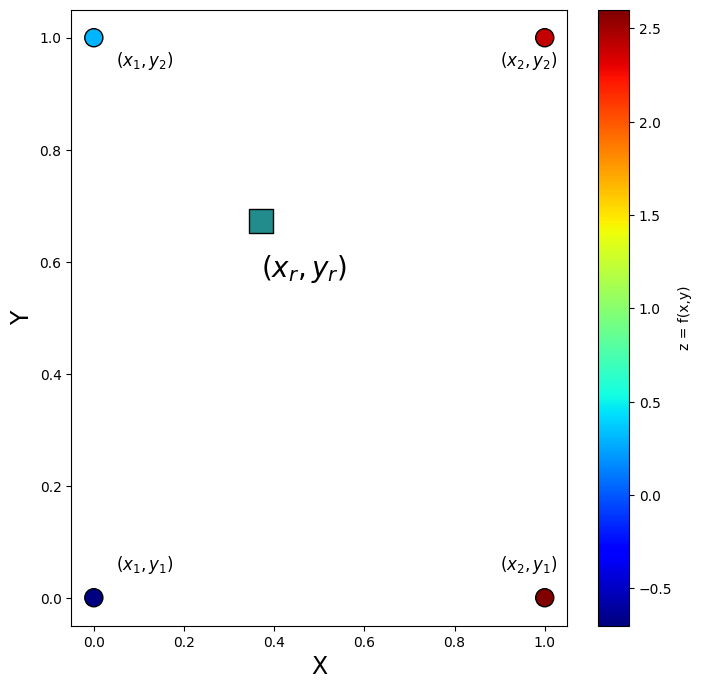

In [21]:
from scipy.interpolate import LinearNDInterpolator

# Define the coordinates of the four known data points.
# The points are listed clockwise, starting at (0, 0).
xi = np.array([0, 0, 1, 1])  # x-coordinates
yi = np.array([0, 1, 1, 0])  # y-coordinates

# Define the corresponding function values z = f(x, y)
zi = np.array([-0.7, 0.3, 2.4, 2.6])

# Randomly generate coordinates within the unit square [0, 1] x [0, 1]
# to calculate the interpolated function value
xr = np.random.uniform()
yr = np.random.uniform()

# Create a linear interpolator using the four known data points.
# LinearNDInterpolator divides the data points into triangles
# and performs linear interpolation within each triangle.
f = LinearNDInterpolator(list(zip(xi, yi)), zi)

# Calculate the interpolated z-value at the randomly generated coordinates
zr = f(xr, yr)

print(f"Triangular interpolation: zr = {zr}")


def interpolate2d(x, y, z, xr, yr):
    # Initialize an array to store the intermediate interpolated values
    # for the two pairs of points
    f_i_r = np.zeros(len(x) // 2)

    i = 0
    j = 0

    # First interpolation step:
    # Perform linear interpolation in the y-direction
    # between each pair of vertically adjacent points
    while i < len(x):
        f_i_r[j] = (
            ((z[i + 1] - z[i]) / (y[i + 1] - y[i])) * (yr - y[i]) + z[i]
        )

        # Move to the next pair of points
        i += 2
        j += 1

    # Second interpolation step:
    # Interpolate between the intermediate values in the x-direction
    for i in range(len(f_i_r) // 2):
        zr = (
            ((f_i_r[i + 1] - f_i_r[i]) / (x[i + 2] - x[i])) * (xr - x[i])
            + f_i_r[i]
        )

    # Return the final bilinearly interpolated z-value
    return zr


# Calculate the interpolated z-value using bilinear interpolation
zr = interpolate2d(xi, yi, zi, xr, yr)

print(f"Bilinear interpolation: zr = {zr}")

vmin = min(np.min(zi), zr)
vmax = max(np.max(zi), zr)

#Visualize
plt.figure(figsize=(8,8))
plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black',vmin=vmin,vmax=vmax)
plt.colorbar(label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)
plt.scatter(xr,yr,c=zr,edgecolor='black',marker='s',s=290,vmin=vmin,vmax=vmax)
plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)



